# Задание 2.10*
## Кривые на сфере Римана: прямая, окружность, парабола, гипербола

### Условие:
Напишите программу (Jupyter Notebook), которая изображает на сфере Римана: а) прямую; б) окружность; в) параболу; г) гиперболу.

### Теория:
Сфера Римана — единичная сфера $S^2:\ X^2+Y^2+Z^2=1$; северный полюс $N=(0,0,1)$ соответствует точке $\infty$. **Стереографическая проекция** из $N$ на плоскость $Z=0$ отождествляет $w=u+iv$ с точкой сферы:
$$
(X,Y,Z)=\Bigl(\frac{2u}{|w|^2+1},\ \frac{2v}{|w|^2+1},\ \frac{|w|^2-1}{|w|^2+1}\Bigr),\qquad
w=\frac{X+iY}{1-Z}.
$$
Свойства: окружности и прямые плоскости переходят в окружности на сфере (прямая — в окружность, проходящую через $N$); отображение конформно. Парабола и гипербола — кривые второго порядка, не являющиеся окружностями, поэтому их образы — **не плоские** сечения сферы. Оба конца параболы уходят в $\infty$, так что её образ — замкнутая кривая, проходящая через $N$ (с касанием ветвей); у гиперболы четыре конца уходят в $\infty$ в направлениях асимптот, и образ — две замкнутые кривые, проходящие через $N$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def to_sphere(w):
    '''обратная стереографическая проекция w -> (X, Y, Z)'''
    w = np.asarray(w, dtype=complex)
    s = abs(w)**2 + 1
    return 2*w.real/s, 2*w.imag/s, (abs(w)**2 - 1)/s

def from_sphere(X, Y, Z):
    return (X + 1j*Y)/(1 - Z)

# параметризации кривых плоскости w = u + i v
t = np.sinh(np.linspace(-9, 9, 6001))           # плотная сетка, уходящая далеко (к N)
tt = np.linspace(0, 2*np.pi, 2001)

curves = {
    'а) прямая  v = u/2 + 1':               t + 1j*(t/2 + 1),
    'б) окружность  |w − (1+0.5i)| = 1.5':    (1 + 0.5j) + 1.5*np.exp(1j*tt),
    'в) парабола  v = u²/2 − 1':            t + 1j*(t**2/2 - 1),
    'г) гипербола  u²/4 − v² = 1':          None,   # две ветви, ниже
}
sh = np.sinh(np.linspace(-6, 6, 4001))
hyper_right = 2*np.sqrt(1 + sh**2) + 1j*sh           # u = 2 cosh s, v = sinh s
hyper_left = -hyper_right.real + 1j*hyper_right.imag
print('построено кривых:', len(curves), '(у гиперболы 2 ветви)')

построено кривых: 4 (у гиперболы 2 ветви)


### Проверка: образ лежит на сфере, обратная проекция возвращает точки; прямая и окружность дают плоские сечения, парабола и гипербола — нет

In [2]:
def planarity(w):
    '''наименьшее сингулярное число матрицы [X Y Z 1]: ≈0 ⇔ точки лежат в одной плоскости'''
    P = np.column_stack([*to_sphere(w), np.ones(len(w))])
    P = P/np.linalg.norm(P, axis=0)
    return np.linalg.svd(P, compute_uv=False)[-1]

w_line = curves['а) прямая  v = u/2 + 1']
w_circ = curves['б) окружность  |w − (1+0.5i)| = 1.5']
w_par = curves['в) парабола  v = u²/2 − 1']
for name, w in [('прямая', w_line), ('окружность', w_circ), ('парабола', w_par),
                ('гипербола (правая ветвь)', hyper_right)]:
    X, Y, Z = to_sphere(w)
    on_sphere = np.allclose(X**2 + Y**2 + Z**2, 1)
    ww = w[abs(w) < 1e3]                              # вдали от ∞ проверяем обратимость
    back = np.allclose(from_sphere(*to_sphere(ww)), ww)
    print(f'{name:26s} на сфере: {on_sphere},  обратная проекция верна: {back},  σ_min(плоскостность) = {planarity(w):.2e}')

прямая                     на сфере: True,  обратная проекция верна: True,  σ_min(плоскостность) = 4.53e-16
окружность                 на сфере: True,  обратная проекция верна: True,  σ_min(плоскостность) = 4.58e-16
парабола                   на сфере: True,  обратная проекция верна: True,  σ_min(плоскостность) = 1.44e-01
гипербола (правая ветвь)   на сфере: True,  обратная проекция верна: True,  σ_min(плоскостность) = 2.18e-02


### Изображение на сфере Римана
Часть кривой на обратной стороне сферы нарисована штрихом.

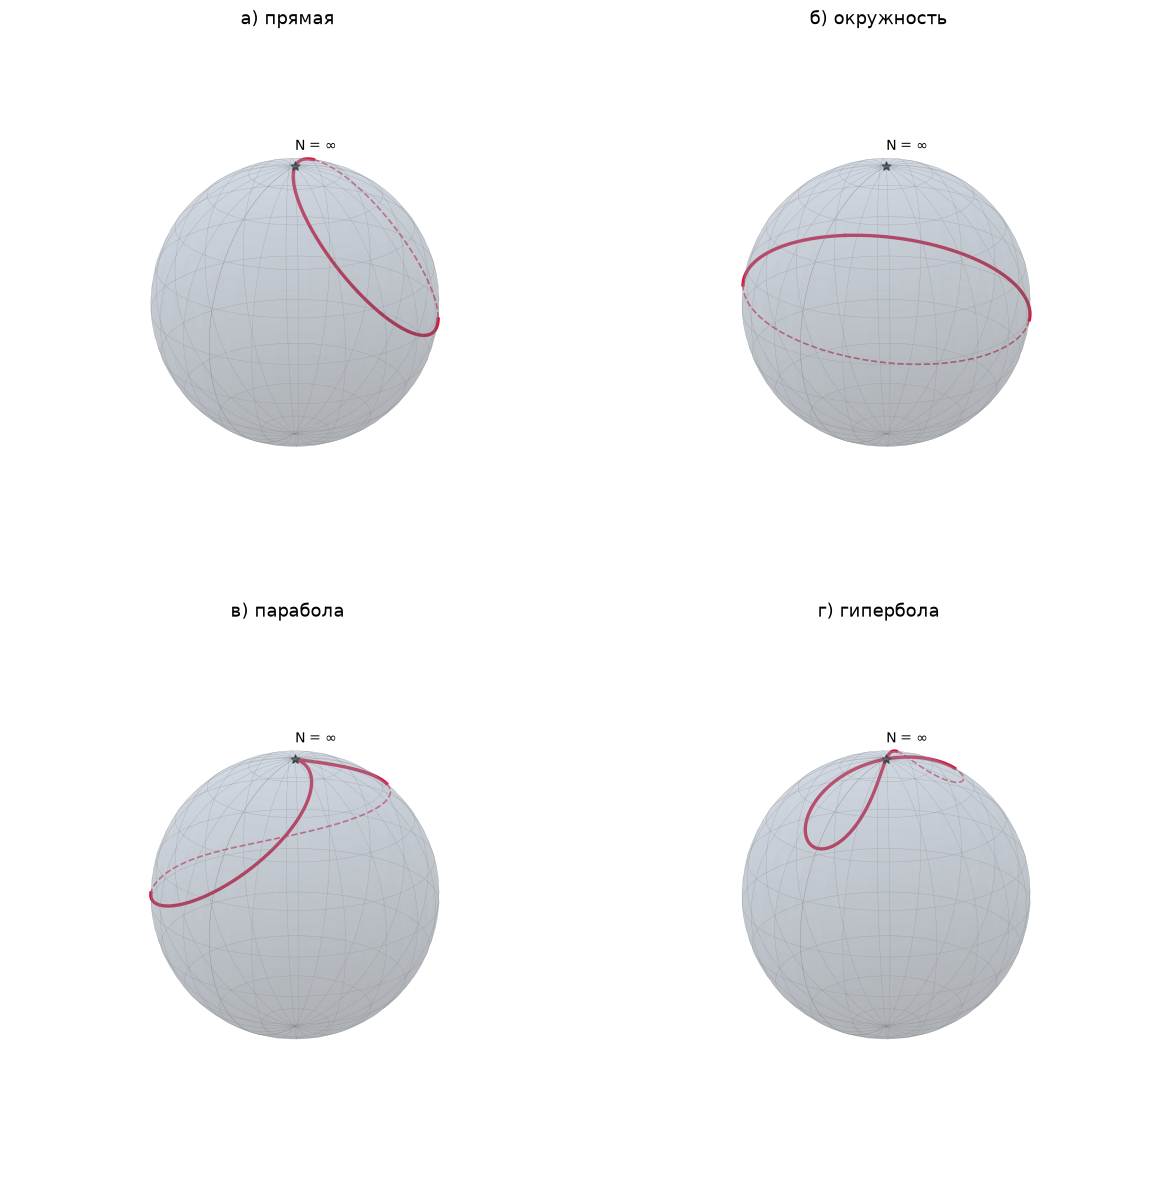

In [3]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

def draw_sphere(ax):
    u = np.linspace(0, 2*np.pi, 80); v = np.linspace(0, np.pi, 40)
    xs, ys, zs = np.outer(np.cos(u), np.sin(v)), np.outer(np.sin(u), np.sin(v)), np.outer(np.ones_like(u), np.cos(v))
    ax.plot_surface(xs, ys, zs, color='lightsteelblue', alpha=0.25, linewidth=0, shade=True)
    ax.plot_wireframe(xs, ys, zs, color='gray', lw=0.25, alpha=0.5, rstride=4, cstride=4)

def draw_curve(ax, w, elev, azim, color):
    X, Y, Z = to_sphere(w)
    d = np.array([np.cos(np.radians(elev))*np.cos(np.radians(azim)),
                  np.cos(np.radians(elev))*np.sin(np.radians(azim)), np.sin(np.radians(elev))])
    front = X*d[0] + Y*d[1] + Z*d[2] >= 0
    ax.plot(np.where(front, X, np.nan), np.where(front, Y, np.nan), np.where(front, Z, np.nan), color=color, lw=2.4)
    ax.plot(np.where(~front, X, np.nan), np.where(~front, Y, np.nan), np.where(~front, Z, np.nan),
            color=color, lw=1.2, ls='--', alpha=0.7)

elev, azim = 22, 35
fig = plt.figure(figsize=(12, 12))
panels = [('а) прямая', [w_line]), ('б) окружность', [w_circ]),
          ('в) парабола', [w_par]), ('г) гипербола', [hyper_right, hyper_left])]
for i, (title, ws) in enumerate(panels, 1):
    ax = fig.add_subplot(2, 2, i, projection='3d')
    draw_sphere(ax)
    for w in ws:
        draw_curve(ax, w, elev, azim, 'crimson')
    ax.scatter([0], [0], [1], color='k', s=40, marker='*')
    ax.text(0, 0, 1.12, 'N = ∞')
    ax.view_init(elev=elev, azim=azim)
    ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()
    ax.set_title(title, fontsize=13)
plt.tight_layout()
plt.show()

### Ответ:

Программа выше с помощью обратной стереографической проекции изображает:
- **прямую** — окружность на сфере, проходящую через $N$;
- **окружность** — окружность на сфере, не проходящую через $N$;
- **параболу** — замкнутую (не плоскую) кривую, проходящую через $N$ (оба конца параболы идут в $\infty$);
- **гиперболу** — две замкнутые кривые, проходящие через $N$ (концы ветвей идут к $\infty$ в направлениях асимптот).

Численная проверка подтверждает: образы прямой и окружности — плоские сечения сферы ($\sigma_{\min}\approx0$), образы параболы и гиперболы — нет.